# Problem Analysis Workshop B — K-Means Clustering

**Course:** PROG8431 — Data Analysis, Mathematics, Modeling and Algorithms

**Team Members:**
- Ubaid Ullah — 9110715
- Rangeetha — 9081357
- Koushik Balne — 9087547

## 1. Project Overview

This workshop continues our Crop Recommendation Analysis project from Assignments 1 and 2.

We will apply K-Means clustering to identify groups of similar growing conditions in our existing dataset. We will examine the resulting clusters and investigate how crop labels are distributed across them.

**Proposed clustering variables:** Rainfall and Temperature.

These variables will be examined before final selection.

In [1]:

# Step 2: Setup and Data Loading

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("Crop_recommendation.csv")
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())


Dataset shape: (2200, 8)
Column names: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



## 3. Data Cleaning and Quality Assessment

Before applying K-Means clustering, we must verify that our dataset is suitable for analysis.

We will examine:
- Missing values and duplicate records.
- Data types and the number of unique crop labels.
- Invalid or unexpected numerical values.
- The distribution of records across crop categories.

We will preserve the original observations unless a clearly justified data-quality issue requires correction.

**Purpose:** Ensure that our clustering analysis uses reliable, consistent data without making unnecessary changes to the dataset.


In [2]:

# Step 3: Data Quality Assessment

clean_df = df.copy()

print("=== Missing Values ===")
print(clean_df.isnull().sum())

print("\n=== Duplicate Records ===")
print("Total duplicates:", clean_df.duplicated().sum())

print("\n=== Data Types ===")
print(clean_df.dtypes)

print("\n=== Crop Categories ===")
print("Unique crop types:", clean_df["label"].nunique())
print(clean_df["label"].value_counts().sort_index())

numeric_cols = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall"
]

print("\n=== Numerical Data Quality ===")
print("Negative nutrient values:",
      (clean_df[["N", "P", "K"]] < 0).sum().sum())

print("Negative rainfall values:",
      (clean_df["rainfall"] < 0).sum())

print("Humidity outside 0–100%:",
      ((clean_df["humidity"] < 0) |
       (clean_df["humidity"] > 100)).sum())

print("pH outside 0–14:",
      ((clean_df["ph"] < 0) |
       (clean_df["ph"] > 14)).sum())


=== Missing Values ===
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

=== Duplicate Records ===
Total duplicates: 0

=== Data Types ===
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object

=== Crop Categories ===
Unique crop types: 22
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64

=== Numerical Data Quality ===
Negative nutrient values: 0
Negati


### Data Quality Findings

The dataset contains 2,200 observations across 22 crop categories, with 100 records per crop.

We found no missing values, exact duplicate records, negative nutrient or rainfall values, or humidity and pH values outside their expected ranges.

All seven environmental and soil variables are numerical, while the crop label is categorical.

No records were removed or modified. We retained the original measurements for the clustering analysis.



## 4. Exploratory Data Analysis (EDA)

Before selecting the two variables for K-Means clustering, we will examine rainfall and temperature to understand their distributions, variability, and potential relationships.

Our analysis will focus on:

- **Rainfall (mm):** The rainfall values recorded in the dataset.
- **Temperature (°C):** The temperature conditions associated with crop records.
- **Variability:** How widely observations differ across the dataset.
- **Potential clustering patterns:** Whether the two variables show meaningful differences that clustering could help explore.

These are candidate variables. Their final selection will depend on the exploratory findings.

**Note:** The dataset does not specify the rainfall accumulation period, so rainfall values will not be interpreted as annual rainfall or irrigation requirements.


In [4]:

# Step 4: Descriptive Statistics for Candidate Variables

candidate_features = ["rainfall", "temperature"]

summary = clean_df[candidate_features].describe().T

# Improve readability for notebook presentation
summary = summary.rename(columns={
    "count": "Records",
    "mean": "Mean",
    "std": "Std. Deviation",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

summary.index = ["Rainfall (mm)", "Temperature (°C)"]

display(
    summary.style
    .format({
    "Records": "{:,.0f}",
    **{col: "{:,.2f}" for col in summary.columns if col != "Records"}
})
    .set_caption("Table 1. Descriptive Statistics for Candidate Clustering Variables")
)


,Records,Mean,Std. Deviation,Minimum,Q1,Median,Q3,Maximum
Rainfall (mm),"2,200",103.46,54.96,20.21,64.55,94.87,124.27,298.56
Temperature (°C),"2,200",25.62,5.06,8.83,22.77,25.60,28.56,43.68


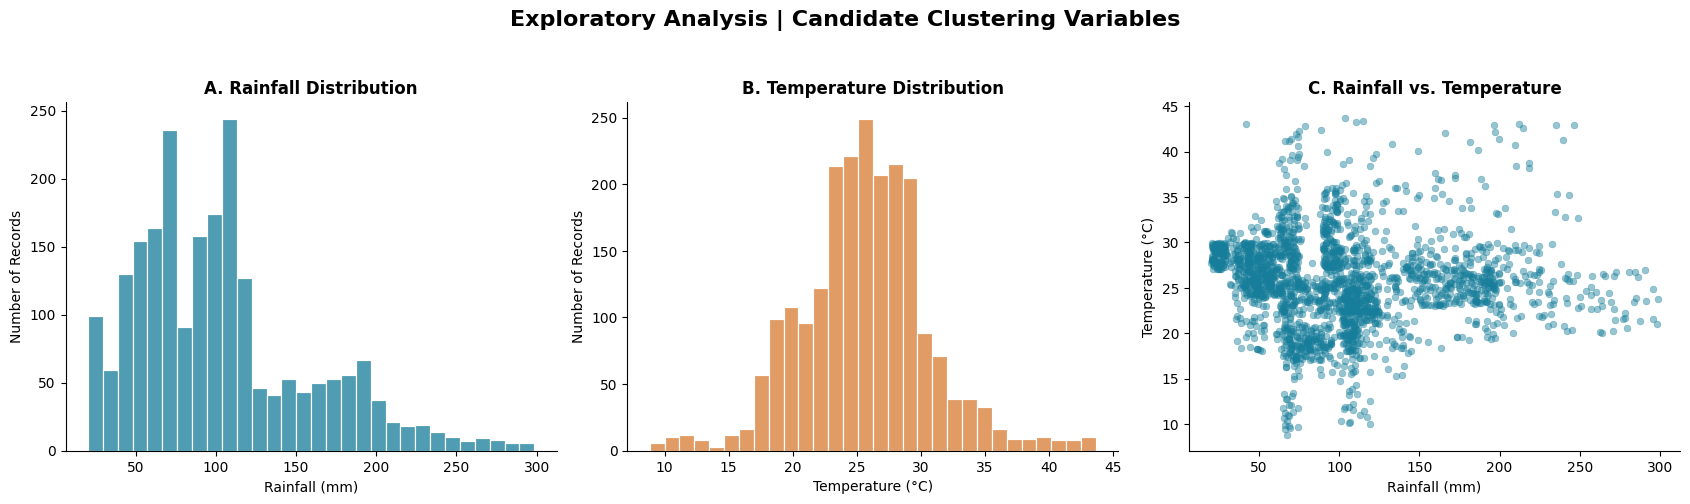

In [5]:

# Step 4: Visual Exploration of Candidate Variables

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.histplot(
    data=clean_df,
    x="rainfall",
    bins=30,
    color="#167D9A",
    edgecolor="white",
    ax=axes[0]
)
axes[0].set_title("A. Rainfall Distribution", fontweight="bold")
axes[0].set_xlabel("Rainfall (mm)")
axes[0].set_ylabel("Number of Records")

sns.histplot(
    data=clean_df,
    x="temperature",
    bins=30,
    color="#D77B32",
    edgecolor="white",
    ax=axes[1]
)
axes[1].set_title("B. Temperature Distribution", fontweight="bold")
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("Number of Records")

sns.scatterplot(
    data=clean_df,
    x="rainfall",
    y="temperature",
    color="#167D9A",
    alpha=0.45,
    s=24,
    edgecolor=None,
    ax=axes[2]
)
axes[2].set_title("C. Rainfall vs. Temperature", fontweight="bold")
axes[2].set_xlabel("Rainfall (mm)")
axes[2].set_ylabel("Temperature (°C)")

fig.suptitle(
    "Exploratory Analysis | Candidate Clustering Variables",
    fontsize=16,
    fontweight="bold",
    y=1.04
)

sns.despine()
plt.tight_layout()
plt.show()



### 4.1 Exploratory Findings and Interpretation

The rainfall histogram shows a right-skewed distribution, with many observations concentrated at lower to moderate rainfall values and fewer observations at higher rainfall levels.

Temperature is more concentrated around 20–30°C, although lower and higher observations are also present.

The scatter plot reveals different combinations of rainfall and temperature, including dense regions and overlapping observations. These patterns provide a reason to investigate clustering, but they do not establish a specific number of clusters.



**Preliminary finding:** Rainfall and temperature were examined as initial candidates. A further comparison with rainfall and humidity was conducted before selecting the final variables, as documented in Section 4.3.





### 4.2 Comparing Candidate Variable Pairs

Two possible variable combinations are being considered:

1. **Rainfall and Temperature:** To explore clustering patterns across recorded precipitation and thermal conditions.
2. **Rainfall and Humidity:** To explore clustering patterns across precipitation and atmospheric moisture conditions.

Both combinations are relevant to the crop dataset. We will examine their relationships, distributions, and visual patterns before finalizing the clustering variables.

The scatter plots are exploratory; visual appearance alone cannot establish which pair produces the best K-Means solution.


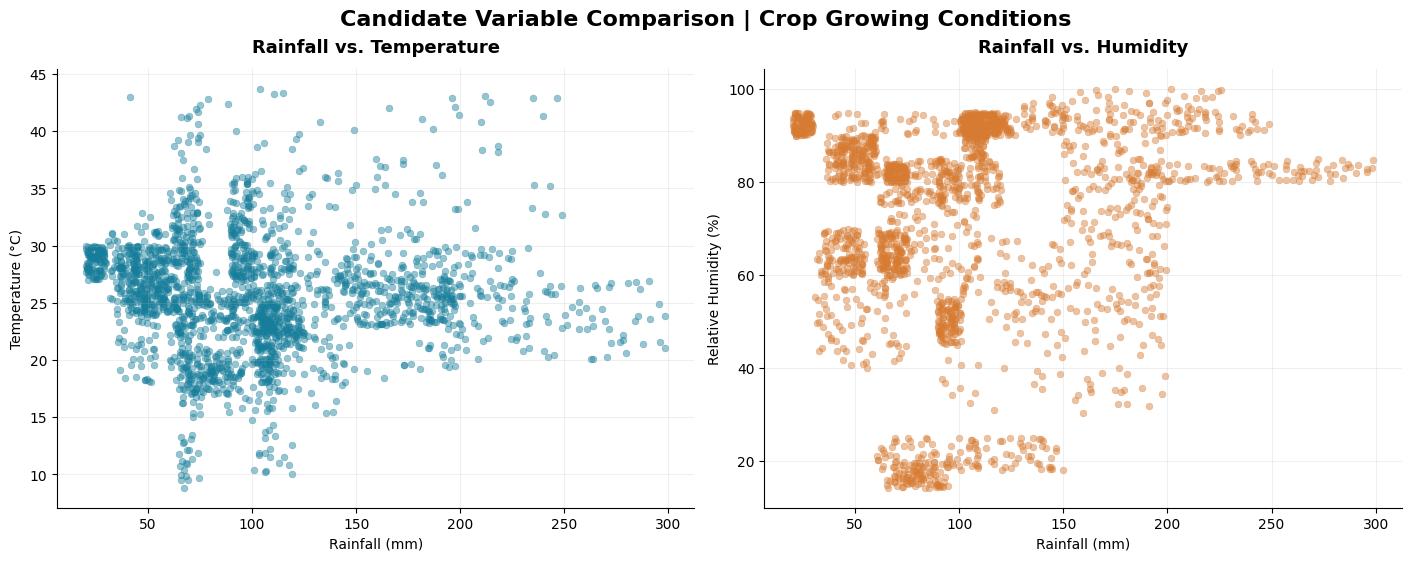

Pearson Correlation with Rainfall
Temperature: -0.030
Humidity:    0.094


In [6]:

# Step 4.2: Compare Candidate Variable Pairs

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.5),
    layout="constrained"
)

pairs = [
    ("temperature", "Temperature (°C)", "#167D9A"),
    ("humidity", "Relative Humidity (%)", "#D77B32")
]

for ax, (variable, ylabel, color) in zip(axes, pairs):
    sns.scatterplot(
        data=clean_df,
        x="rainfall",
        y=variable,
        color=color,
        alpha=0.45,
        s=24,
        edgecolor=None,
        ax=ax
    )

    ax.set_title(
        f"Rainfall vs. {variable.title()}",
        fontsize=13,
        fontweight="bold",
        pad=12
    )
    ax.set_xlabel("Rainfall (mm)")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    sns.despine(ax=ax)

fig.suptitle(
    "Candidate Variable Comparison | Crop Growing Conditions",
    fontsize=16,
    fontweight="bold"
)

plt.show()

# Quantify the relationships
comparison = clean_df[
    ["rainfall", "temperature", "humidity"]
].corr(method="pearson")

print("Pearson Correlation with Rainfall")
print(f"Temperature: {comparison.loc['rainfall', 'temperature']:.3f}")
print(f"Humidity:    {comparison.loc['rainfall', 'humidity']:.3f}")



### 4.3 EDA Findings and Variable Selection Decision

We compared two candidate variable pairs: rainfall–temperature and rainfall–humidity.

Pearson correlation showed almost no linear relationship between rainfall and temperature (r = -0.030), and a very weak positive relationship between rainfall and humidity (r = 0.094). Neither result establishes the existence or quality of clusters.

The rainfall–humidity scatter plot showed more visually distinct concentrations, particularly at lower and higher humidity levels. This makes the pair useful for exploring differences in moisture-related growing conditions.

**Selected variables:**
- **Rainfall (mm):** Represents recorded precipitation conditions.
- **Humidity (%):** Represents recorded atmospheric moisture conditions.

**Justification:** These two variables are relevant to the project's environmental focus, show potentially interesting groupings, and provide a clear basis for interpreting moisture-related clusters.

The selection is exploratory. Cluster quality will be evaluated after standardization and K-Means rather than inferred from appearance alone.
